# U-Net for crop-weed segmentation

This notebook contains the U-Net model for the same three-class RGB segmentation task and fixed source-image split used by the earlier notebooks.

In [9]:
import tensorflow as tf
import numpy as np

tf.keras.utils.set_random_seed(42)
PATCH_SIZE = 256
NUM_CLASSES = 3
IGNORE_LABEL = 255
CLASS_COLORS = np.array([[199, 199, 199], [31, 119, 180], [255, 127, 14]], dtype=np.uint8)


## 5.1 U-Net architecture

In [10]:
def unet_block(inputs, filters, name):
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name}_conv1')(inputs)
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', activation='relu', name=f'{name}_conv2')(x)
    return x

def build_unet(input_shape=(PATCH_SIZE, PATCH_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = tf.keras.Input(shape=input_shape, name='rgb_input')

    # Encoder: preserve feature maps for skip connections.
    encoder_1 = unet_block(inputs, 16, 'encoder_1')
    pool_1 = tf.keras.layers.MaxPooling2D(2, name='pool_1')(encoder_1)
    encoder_2 = unet_block(pool_1, 32, 'encoder_2')
    pool_2 = tf.keras.layers.MaxPooling2D(2, name='pool_2')(encoder_2)
    encoder_3 = unet_block(pool_2, 64, 'encoder_3')
    pool_3 = tf.keras.layers.MaxPooling2D(2, name='pool_3')(encoder_3)

    bottleneck = unet_block(pool_3, 128, 'bottleneck')
    bottleneck = tf.keras.layers.SpatialDropout2D(0.2, name='bottleneck_dropout')(bottleneck)

    # Decoder: upsample and concatenate the matching encoder feature map.
    up_3 = tf.keras.layers.UpSampling2D(2, name='up_3')(bottleneck)
    decoder_3 = unet_block(tf.keras.layers.Concatenate(name='skip_3')([up_3, encoder_3]), 64, 'decoder_3')
    up_2 = tf.keras.layers.UpSampling2D(2, name='up_2')(decoder_3)
    decoder_2 = unet_block(tf.keras.layers.Concatenate(name='skip_2')([up_2, encoder_2]), 32, 'decoder_2')
    up_1 = tf.keras.layers.UpSampling2D(2, name='up_1')(decoder_2)
    decoder_1 = unet_block(tf.keras.layers.Concatenate(name='skip_1')([up_1, encoder_1]), 16, 'decoder_1')

    outputs = tf.keras.layers.Conv2D(num_classes, 1, padding='same', activation='softmax', name='class_probabilities')(decoder_1)
    return tf.keras.Model(inputs, outputs, name='unet')

unet = build_unet()
unet.summary()
test_output = unet(tf.zeros((1, PATCH_SIZE, PATCH_SIZE, 3)))
if tuple(test_output.shape) != (1, PATCH_SIZE, PATCH_SIZE, NUM_CLASSES):
    raise ValueError(f'Unexpected U-Net output shape: {test_output.shape}')
if not np.allclose(tf.reduce_sum(test_output, axis=-1).numpy(), 1.0, atol=1e-5):
    raise ValueError('U-Net probabilities do not sum to one.')
print('U-Net output shape:', test_output.shape)


Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_conv1     │ (None, 256, 256,  │        448 │ rgb_input[0][0]   │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_conv2     │ (None, 256, 256,  │      2,320 │ encoder_1_conv1[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_1              │ (None, 128, 128,  │          0 │ encoder_1_conv2[… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2_conv1     │ (None, 128, 128,  │      4,640 │ pool_1[0][0]      │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2_conv2     │ (None, 128, 128,  │      9,248 │ encoder_2_conv1[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_2              │ (None, 64, 64,    │          0 │ encoder_2_conv2[… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_3_conv1     │ (None, 64, 64,    │     18,496 │ pool_2[0][0]      │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_3_conv2     │ (None, 64, 64,    │     36,928 │ encoder_3_conv1[… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool_3              │ (None, 32, 32,    │          0 │ encoder_3_conv2[… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv1    │ (None, 32, 32,    │     73,856 │ pool_3[0][0]      │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_conv2    │ (None, 32, 32,    │    147,584 │ bottleneck_conv1… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_dropout  │ (None, 32, 32,    │          0 │ bottleneck_conv2… │
│ (SpatialDropout2D)  │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_3 (UpSampling2D) │ (None, 64, 64,    │          0 │ bottleneck_dropo… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_3              │ (None, 64, 64,    │          0 │ up_3[0][0],       │
│ (Concatenate)       │ 192)              │            │ encoder_3_conv2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_3_conv1     │ (None, 64, 64,    │    110,656 │ skip_3[0][0]      │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_3_conv2     │ (None, 64, 64,    │     36,928 │ decoder_3_conv1[

 Total params: 487,331 (1.86 MB)

 Trainable params: 487,331 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

U-Net output shape: (1, 256, 256, 3)


## 5.2 U-Net training

In [11]:
from pathlib import Path
import json
import math
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'project_plan.md').exists():
    PROJECT_ROOT = PROJECT_ROOT / 'final-project'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
FIGURE_DIR = ARTIFACT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
split_record = json.loads((ARTIFACT_DIR / 'split.json').read_text(encoding='utf-8'))
train_images = [PROJECT_ROOT / p for p in split_record['train_images']]
val_images = [PROJECT_ROOT / p for p in split_record['validation_images']]
def mask_for(path): return path.parent.parent / 'msk' / f'{path.stem}.png'
train_masks = [mask_for(p) for p in train_images]
val_masks = [mask_for(p) for p in val_images]

def generate_patches(image_paths, mask_paths):
    for image_path, mask_path in zip(image_paths, mask_paths):
        with Image.open(image_path) as image, Image.open(mask_path) as mask:
            rgb = np.asarray(image.convert('RGB'))
            mask_rgb = np.asarray(mask.convert('RGB'))
        labels = np.full(mask_rgb.shape[:2], IGNORE_LABEL, dtype=np.uint8)
        for class_id, color in enumerate(CLASS_COLORS):
            labels[np.all(mask_rgb == color, axis=-1)] = class_id
        for y in range(0, labels.shape[0], PATCH_SIZE):
            for x in range(0, labels.shape[1], PATCH_SIZE):
                height, width = min(PATCH_SIZE, labels.shape[0] - y), min(PATCH_SIZE, labels.shape[1] - x)
                image_patch = np.zeros((PATCH_SIZE, PATCH_SIZE, 3), dtype=np.float32)
                label_patch = np.full((PATCH_SIZE, PATCH_SIZE), IGNORE_LABEL, dtype=np.int32)
                weight_patch = np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
                image_patch[:height, :width] = rgb[y:y + height, x:x + width] / 255.0
                label_patch[:height, :width] = labels[y:y + height, x:x + width]
                weight_patch[:height, :width] = (label_patch[:height, :width] != IGNORE_LABEL).astype(np.float32)
                safe_labels = np.where(weight_patch > 0, label_patch, 0).astype(np.int32)
                yield image_patch, safe_labels, weight_patch

def make_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_generator(lambda: generate_patches(image_paths, mask_paths), output_signature=(tf.TensorSpec((PATCH_SIZE, PATCH_SIZE, 3), tf.float32), tf.TensorSpec((PATCH_SIZE, PATCH_SIZE), tf.int32), tf.TensorSpec((PATCH_SIZE, PATCH_SIZE), tf.float32)))
    if training: dataset = dataset.shuffle(64, seed=42, reshuffle_each_iteration=True)
    return dataset.batch(8)

def count_patches(paths):
    total = 0
    for path in paths:
        with Image.open(path) as image: total += math.ceil(image.height / PATCH_SIZE) * math.ceil(image.width / PATCH_SIZE)
    return total

train_steps = math.ceil(count_patches(train_images) / 8)
val_steps = math.ceil(count_patches(val_images) / 8)
def materialize_patches(image_paths, mask_paths):
    patches = list(generate_patches(image_paths, mask_paths))
    images, labels, weights = zip(*patches)
    return np.stack(images), np.stack(labels), np.stack(weights)

train_arrays = materialize_patches(train_images, train_masks)
val_arrays = materialize_patches(val_images, val_masks)
train_dataset = tf.data.Dataset.from_tensor_slices(train_arrays).shuffle(64, seed=42, reshuffle_each_iteration=True).batch(8).prefetch(tf.data.AUTOTUNE)
val_dataset = tf.data.Dataset.from_tensor_slices(val_arrays).batch(8).prefetch(tf.data.AUTOTUNE)
print('Training steps:', train_steps, 'Validation steps:', val_steps)


Training steps: 372 Validation steps: 124


Epoch 1/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - loss: 0.0635
Epoch 1: val_loss improved from None to 0.03334, saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/unet_best.keras

Epoch 1: finished saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/unet_best.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 157s 417ms/step - loss: 0.0635 - val_loss: 0.0333
Epoch 2/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - loss: 0.0226
Epoch 2: val_loss improved from 0.03334 to 0.03106, saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/unet_best.keras

Epoch 2: finished saving model to /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/unet_best.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 155s 416ms/step - loss: 0.0226 - val_loss: 0.0311
Epoch 3/30
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - loss: 0.0242
Epoch 3: val_loss improved from 0.03106 to 0.03023, saving model to /Users/eva/Documents/Assignments/DAT

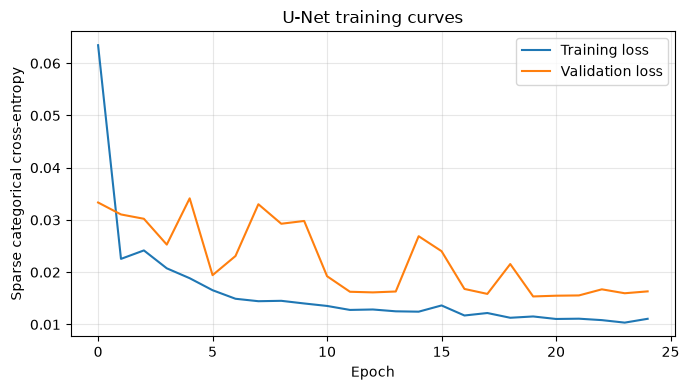

Saved: /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/unet_best.keras


In [12]:
unet.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.SparseCategoricalCrossentropy())
UNET_CHECKPOINT = ARTIFACT_DIR / 'unet_best.keras'
unet_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, mode='min', restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(UNET_CHECKPOINT, monitor='val_loss', mode='min', save_best_only=True, verbose=1),
]
UNET_MAX_EPOCHS = 30
unet_history = unet.fit(train_dataset, validation_data=val_dataset, epochs=UNET_MAX_EPOCHS, callbacks=unet_callbacks, shuffle=False)
history_values = {key: [float(value) for value in values] for key, values in unet_history.history.items()}
(ARTIFACT_DIR / 'unet_history.json').write_text(json.dumps(history_values, indent=2) + '\n', encoding='utf-8')
import matplotlib.pyplot as plt
figure, axis = plt.subplots(figsize=(7, 4))
axis.plot(history_values['loss'], label='Training loss')
axis.plot(history_values['val_loss'], label='Validation loss')
axis.set(xlabel='Epoch', ylabel='Sparse categorical cross-entropy', title='U-Net training curves')
axis.legend(); axis.grid(alpha=0.3); figure.tight_layout()
figure.savefig(FIGURE_DIR / 'unet_curves.png', dpi=150)
plt.show(); plt.close(figure)
print('Saved:', UNET_CHECKPOINT)


## 5.3 U-Net validation evaluation

In [13]:
UNET_EVALUATION_MODEL = tf.keras.models.load_model(UNET_CHECKPOINT, compile=False)
confusion = tf.zeros((NUM_CLASSES, NUM_CLASSES), dtype=tf.float64)
for images, labels, pixel_weights in val_dataset.take(val_steps):
    probabilities = UNET_EVALUATION_MODEL(images, training=False)
    predictions = tf.argmax(probabilities, axis=-1, output_type=tf.int32)
    valid = tf.reshape(pixel_weights > 0, [-1])
    confusion += tf.math.confusion_matrix(
        tf.boolean_mask(tf.reshape(labels, [-1]), valid),
        tf.boolean_mask(tf.reshape(predictions, [-1]), valid),
        num_classes=NUM_CLASSES, dtype=tf.float64,
    )
true_positives = tf.linalg.diag_part(confusion)
actual = tf.reduce_sum(confusion, axis=1)
predicted = tf.reduce_sum(confusion, axis=0)
iou = tf.math.divide_no_nan(true_positives, actual + predicted - true_positives).numpy()
dice = tf.math.divide_no_nan(2.0 * true_positives, actual + predicted).numpy()
unet_scores = {'iou': iou.tolist(), 'dice': dice.tolist(), 'mean_iou': float(iou.mean()), 'weed_iou': float(iou[2])}
class_names = ['background/soil', 'crop/sorghum', 'weeds']
print('U-Net validation confusion matrix:\n', confusion.numpy().astype(np.int64))
for class_id, name in enumerate(class_names):
    print(f'{name}: IoU={iou[class_id]:.4f}, Dice={dice[class_id]:.4f}')
print(f'U-Net Mean IoU: {unet_scores["mean_iou"]:.4f}')
print(f'U-Net Weed IoU: {unet_scores["weed_iou"]:.4f}')
(ARTIFACT_DIR / 'UNET_VALIDATION_SCORES.json').write_text(json.dumps(unet_scores, indent=2) + '\n', encoding='utf-8')


U-Net validation confusion matrix:
 [[57896347    90737    91573]
 [  112127  1091208    24289]
 [   34895    26558   517834]]
background/soil: IoU=0.9943, Dice=0.9972
crop/sorghum: IoU=0.8114, Dice=0.8959
weeds: IoU=0.7449, Dice=0.8538
U-Net Mean IoU: 0.8502
U-Net Weed IoU: 0.7449


2026-10-11 10:08:21.505288: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


243